## Step 1 : Setup
This section is meant for setting up variables, initalizing our quantum circuit and any additional parameters required for hashing

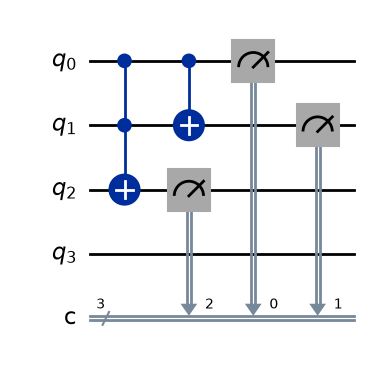

In [14]:
from qiskit import QuantumCircuit
from qiskit.circuit.classical import expr, types
from qiskit_aer.primitives import SamplerV2

coin_positions = ("000", "001", "010", "011", "100", "101", "110", "111")
test = "1001"
size_q = 4

qc = QuantumCircuit(size_q, 3)

for qtarget in range(size_q - 2, 0, -1):
    control = list(range(qtarget))
    qc.mcx(control, qtarget)   
    
qcoin = QuantumCircuit(1)
qcoin.h(0)
qcoin.measure_all()

sampler = SamplerV2()
job = sampler.run([qcoin], shots=1000)

results = job.result()
counts = results[0].data.meas.get_counts()

if counts['1'] > counts['0']:
    qc.mcx([0], 3)

qc.measure([0,1,2], [0,1,2])
qc.draw("mpl")

{'000': 128}


## Step 2: Hashing Algorithm

## Step 3: Results